# 🤖 AutoML on the Athletes Dataset
### MLflow + FLAML (platform AutoML) · H2O AutoML · comparison with the Part A model

| | |
|:--|:--|
| **Data** | the same cleaned `athletes.csv` rows, features and **train/test split** produced by the Part A pipeline (`athletes-mlops/data/processed/*.parquet`) |
| **Target** | `total_lift` = deadlift + clean & jerk + snatch + back squat |
| **Platform** | MLflow (tracking) with **FLAML** as the AutoML engine: every AutoML run, leaderboard and plot is logged to the same MLflow store as Part A |
| **Second engine** | **H2O AutoML** (Q9) |
| **Part A baseline** | `RandomForestRegressor`, feature version **v2**, hyper-parameters **`hp_light`** (best Part A run) |

> **Before running:** run `python -m src.pipeline` once in `athletes-mlops/` so the `data/processed/*.parquet` files exist. Then set `REPO` in the config cell below.

**Question map**

| Q | Where |
|:--|:--|
| 1 · Load data | §1 |
| 2 · AutoML best model | §2 |
| 3 · Data insights | §1.2 and §3 |
| 4 · Top-5 features | §4 |
| 5 · Top-3 models by validation score (all / top-3 features) | §5 |
| 6 · Top-3 models by speed (all / top-3 features) | §6 |
| 7 · vs. Part A model | §7 |
| 8 · No-code / low-code / full-code? | §8 |
| 9 · Repeat 2–5 with H2O | §9 |
| Summary for the report | §10 |

## ⚙️ 0 · Setup

One-time install on the Mac, inside the conda env from Part A (H2O needs a Java runtime, which conda can install):

```bash
conda activate athletes-mlops
conda install -c conda-forge openjdk=17 lightgbm xgboost -y
pip install "flaml[automl]" h2o tabulate
```

In [1]:
!pip -q install "flaml[automl]" h2o tabulate

In [2]:
import json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
from flaml import AutoML
from flaml.automl.data import get_output_from_log
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.model_selection import cross_val_score, KFold

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

/opt/anaconda3/envs/athletes-mlops/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# ── CONFIG ──────────────────────────────────────────────────────────────────────
REPO          = Path("~/Downloads/athletes-mlops").expanduser()   # Part A repo
PROCESSED     = REPO / "data" / "processed"
OUT           = Path("automl_outputs"); OUT.mkdir(exist_ok=True)

TARGET        = "total_lift"
SEED          = 42
N_TOP_FEATS   = 3        # "if you have to choose a number put in 3"
FLAML_BUDGET  = 300      # seconds per FLAML run   (2 runs)
H2O_BUDGET    = 300      # seconds per H2O run     (2 runs)
CV_FOLDS      = 5        # both engines validate with 5-fold CV on the TRAIN split

# Best Part A configuration (RandomForest · v2 features · hp_light)
PART_A_PARAMS = dict(n_estimators=100, max_depth=10, min_samples_leaf=5,
                     max_features=0.5, random_state=SEED, n_jobs=-1)

# Same MLflow store as Part A, separate experiment
mlflow.set_tracking_uri(f"sqlite:///{REPO / 'mlflow.db'}")
EXPERIMENT = "athletes-automl"
if mlflow.get_experiment_by_name(EXPERIMENT) is None:
    mlflow.create_experiment(EXPERIMENT,
        artifact_location=(REPO / "mlartifacts" / "automl").resolve().as_uri())
mlflow.set_experiment(EXPERIMENT)
print("MLflow:", mlflow.get_tracking_uri(), "| experiment:", EXPERIMENT)

MLflow: sqlite:////Users/efrainrodriguez/Downloads/athletes-mlops/mlflow.db | experiment: athletes-automl


## 📥 1 · Load the (same) athletes dataset

We read the feature tables the Part A pipeline wrote for the Feast offline store and join them on `athlete_id`. Re-using the stored `split` column means **AutoML trains and tests on exactly the rows Part A did**, so §7 is a fair comparison.

In [8]:
PROCESSED = "/Users/efrainrodriguez/Documents/GitHub/MLOPS/data/processed/"

In [11]:
basic  = pd.read_parquet(PROCESSED + "athlete_basic.parquet").drop(columns="event_timestamp")
eng    = pd.read_parquet(PROCESSED + "athlete_engineered.parquet").drop(columns="event_timestamp")
labels = pd.read_parquet(PROCESSED + "labels.parquet").drop(columns="event_timestamp")

df = labels.merge(basic, on="athlete_id").merge(eng, on="athlete_id")
FEATURES_ALL = [c for c in list(basic.columns) + list(eng.columns) if c != "athlete_id"]

train = df[df["split"] == "train"].reset_index(drop=True)
test  = df[df["split"] == "test"].reset_index(drop=True)
print(f"rows: {len(df):,}  ·  train {len(train):,}  ·  test {len(test):,}  ·  features {len(FEATURES_ALL)}")
print(FEATURES_ALL)

rows: 30,029  ·  train 24,023  ·  test 6,006  ·  features 14
['age', 'height', 'weight', 'gender_male', 'bmi', 'region_code', 'howlong_ord', 'eat_n', 'background_n', 'experience_n', 'schedule_n', 'exp_began_with_coach', 'sched_multi_daily', 'bg_college_sports']


### 1.2 · Quick profile (input to Q3)

,mean,std,min,50%,max
age,32.124,7.435,18.000,31.000,56.000
height,68.872,3.775,52.000,69.000,83.000
weight,177.131,32.400,5.000,178.000,474.000
gender_male,0.727,0.446,0.000,1.000,1.000
bmi,26.113,3.485,0.976,25.824,62.879
region_code,9.220,4.258,0.000,9.000,16.000
howlong_ord,2.309,1.041,0.000,2.000,4.000
eat_n,1.381,0.583,1.000,1.000,6.000
background_n,1.480,0.671,1.000,1.000,6.000
experience_n,2.094,1.330,1.000,2.000,7.000


missing values: 0


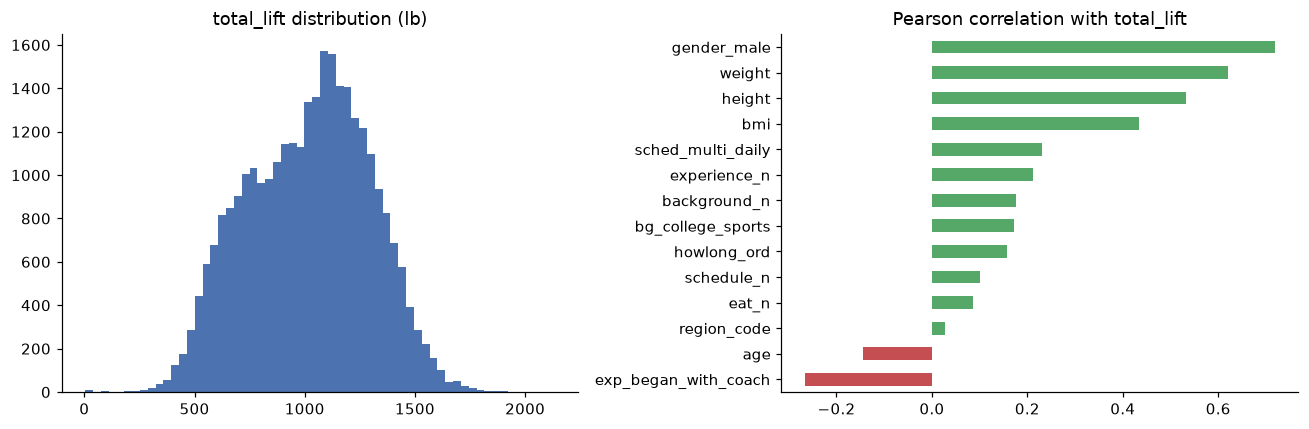

                 count      mean     std
gender_male                             
0            8,206.000   692.554 142.149
1           21,823.000 1,139.888 209.333


In [12]:
display(df[FEATURES_ALL + [TARGET]].describe().T[["mean", "std", "min", "50%", "max"]])
print("missing values:", int(df[FEATURES_ALL].isna().sum().sum()))

corr = df[FEATURES_ALL + [TARGET]].corr(numeric_only=True)[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df[TARGET], bins=60, color="#4C72B0"); ax[0].set_title("total_lift distribution (lb)")
corr.plot.barh(ax=ax[1], color=np.where(corr > 0, "#55A868", "#C44E52"))
ax[1].set_title("Pearson correlation with total_lift")
plt.tight_layout(); fig.savefig(OUT / "data_profile.png"); plt.show()
print(df.groupby("gender_male")[TARGET].describe()[["count", "mean", "std"]])

## 🛠️ Helpers

In [13]:
def rmse(y, p):
    return float(np.sqrt(mean_squared_error(y, p)))

def time_fit_predict(make_model, X_tr, y_tr, X_te):
    # Refit once on the full train split and time fit + batch prediction.
    model = make_model()
    t0 = time.perf_counter(); model.fit(X_tr, y_tr); fit_s = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = model.predict(X_te); pred_s = time.perf_counter() - t0
    return model, np.asarray(pred), fit_s, 1000 * pred_s / len(X_te) * 1000   # ms per 1k rows

def run_flaml(features, tag):
    # One FLAML AutoML run on `features`, logged to MLflow. Returns (automl, leaderboard).
    log_file = OUT / f"flaml_{tag}.log"
    automl = AutoML()
    with mlflow.start_run(run_name=f"flaml_{tag}"):
        t0 = time.perf_counter()
        automl.fit(train[features], train[TARGET], task="regression", metric="rmse",
                   time_budget=FLAML_BUDGET, eval_method="cv", n_splits=CV_FOLDS,
                   estimator_list=FLAML_ESTIMATORS, seed=SEED, verbose=1,
                   log_file_name=str(log_file), mlflow_logging=False)
        search_s = time.perf_counter() - t0

        # Leaderboard: best config of every model family, refit once on train for timing
        rows = []
        for est, val_rmse in automl.best_loss_per_estimator.items():
            if val_rmse is None or not np.isfinite(val_rmse):
                continue                      # family never finished a trial within budget
            best = automl.best_model_for_estimator(est)
            make = lambda b=best: type(b)(task="regression", **b.params)
            _, pred, fit_s, ms_1k = time_fit_predict(make, train[features], train[TARGET], test[features])
            rows.append(dict(model=est, val_rmse=float(val_rmse), test_rmse=rmse(test[TARGET], pred),
                             test_r2=r2_score(test[TARGET], pred), fit_s=fit_s, predict_ms_per_1k=ms_1k,
                             config=json.dumps({k: (round(v, 4) if isinstance(v, float) else v)
                                                for k, v in automl.best_config_per_estimator[est].items()})))
        lb = pd.DataFrame(rows).sort_values("val_rmse").reset_index(drop=True)

        test_pred = automl.predict(test[features])
        mlflow.log_params({"engine": "flaml", "features": ",".join(features), "n_features": len(features),
                           "time_budget_s": FLAML_BUDGET, "cv_folds": CV_FOLDS,
                           "best_estimator": automl.best_estimator})
        mlflow.log_metrics({"best_val_rmse": automl.best_loss, "test_rmse": rmse(test[TARGET], test_pred),
                            "test_r2": r2_score(test[TARGET], test_pred), "search_seconds": search_s,
                            "best_model_fit_seconds": automl.best_config_train_time})
        lb.to_csv(OUT / f"flaml_leaderboard_{tag}.csv", index=False)
        mlflow.log_artifact(str(OUT / f"flaml_leaderboard_{tag}.csv"))
        mlflow.log_artifact(str(log_file))
    print(f"[{tag}] best = {automl.best_estimator}  val RMSE = {automl.best_loss:,.1f}  "
          f"test RMSE = {rmse(test[TARGET], test_pred):,.1f}  ({search_s:,.0f}s search)")
    return automl, lb

def top3_tables(lb, score_col="val_rmse", speed_col="fit_s", cols=None):
    cols = cols or list(lb.columns)
    by_score = lb.nsmallest(3, score_col)[cols].reset_index(drop=True)
    by_speed = lb.nsmallest(3, speed_col)[cols].reset_index(drop=True)
    by_score.index = by_speed.index = [1, 2, 3]
    return by_score, by_speed

## 🚀 2 · AutoML on the platform (MLflow + FLAML) — all features

FLAML searches several model families and their hyper-parameters at the same time, spending more of the budget on the families that look promising (cost-frugal search). Validation = **5-fold CV RMSE on the train split**. The held-out test split is only used for reporting.

In [14]:
FLAML_ESTIMATORS = ["lgbm", "xgboost", "xgb_limitdepth", "rf", "extra_tree", "histgb",
                    "enet", "lassolars", "sgd", "kneighbor"]
try:
    import catboost  # noqa: F401  (optional)
    FLAML_ESTIMATORS.append("catboost")
except ImportError:
    pass

automl_all, lb_flaml_all = run_flaml(FEATURES_ALL, "all")
print("Best config:", automl_all.best_config)
lb_flaml_all

[all] best = xgb_limitdepth  val RMSE = 143.4  test RMSE = 143.9  (300s search)
Best config: {'n_estimators': 368, 'max_depth': 4, 'min_child_weight': np.float64(0.23232591727904786), 'learning_rate': np.float64(0.037631950083674315), 'subsample': np.float64(0.874361341734329), 'colsample_bylevel': np.float64(0.8369824100174466), 'colsample_bytree': 1.0, 'reg_alpha': np.float64(0.0029226195203485247), 'reg_lambda': np.float64(16.95573286163502)}


,model,val_rmse,test_rmse,test_r2,fit_s,predict_ms_per_1k,config
0,xgb_limitdepth,143.351,143.891,0.730,0.322,0.732,"{""n_estimators"": 368, ""max_depth"": 4, ""min_chi..."
1,xgboost,143.367,143.955,0.730,2.997,3.416,"{""n_estimators"": 3700, ""max_leaves"": 4, ""min_c..."
2,lgbm,143.663,144.208,0.729,0.339,1.243,"{""n_estimators"": 432, ""num_leaves"": 5, ""min_ch..."
3,histgb,145.244,145.630,0.724,1.598,1.080,"{""n_estimators"": 75, ""max_leaves"": 76, ""min_sa..."
4,rf,149.201,149.907,0.707,0.097,2.368,"{""n_estimators"": 11, ""max_features"": 0.6151, ""..."
5,lassolars,153.037,152.468,0.697,0.003,0.086,"{""alpha"": 0.0907, ""fit_intercept"": true, ""eps""..."
6,enet,153.076,152.493,0.697,0.723,0.109,"{""alpha"": 0.0424, ""l1_ratio"": 0.9343, ""selecti..."
7,extra_tree,154.894,155.953,0.683,0.030,2.345,"{""n_estimators"": 4, ""max_features"": 0.6917, ""m..."
8,sgd,172.337,159.842,0.667,0.368,0.215,"{""penalty"": ""l1"", ""alpha"": 0.0001, ""l1_ratio"":..."
9,kneighbor,179.876,179.832,0.579,0.006,6.625,"{""n_neighbors"": 32}"


## 🔎 3 · Data insights from the AutoML run

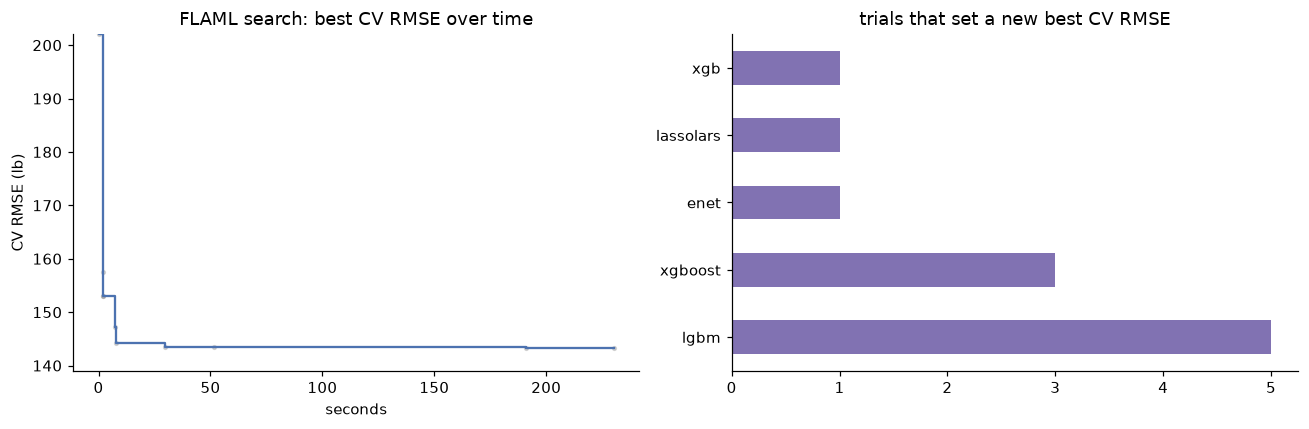

best model found after 230s of 300s


In [17]:
# 3a · Search history: how fast did validation RMSE improve, and which families won trials?
t_hist, best_err_hist, err_hist, cfg_hist, _ = get_output_from_log(str(OUT / "flaml_all.log"), FLAML_BUDGET)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].step(t_hist, best_err_hist, where="post", color="#4C72B0")
ax[0].scatter(t_hist, err_hist, s=6, alpha=.3, color="grey")
ax[0].set(title="FLAML search: best CV RMSE over time", xlabel="seconds", ylabel="CV RMSE (lb)")
ax[0].set_ylim(min(best_err_hist) * 0.97, np.percentile(err_hist, 90))
trials = pd.Series([c["Current Learner"] for c in cfg_hist]).value_counts()
trials.plot.barh(ax=ax[1], color="#8172B2"); ax[1].set_title("trials that set a new best CV RMSE")
plt.tight_layout(); fig.savefig(OUT / "flaml_search.png"); plt.show()
print(f"best model found after {automl_all.time_to_find_best_model:,.0f}s of {FLAML_BUDGET}s")


,MAE,mean residual
sex,,
female,85.156,-0.636
male,119.516,1.480


,MAE,mean residual
training_years,,
0,138.997,7.924
1,118.841,-1.580
2,108.798,-1.816
3,105.083,1.786
4,102.037,5.796


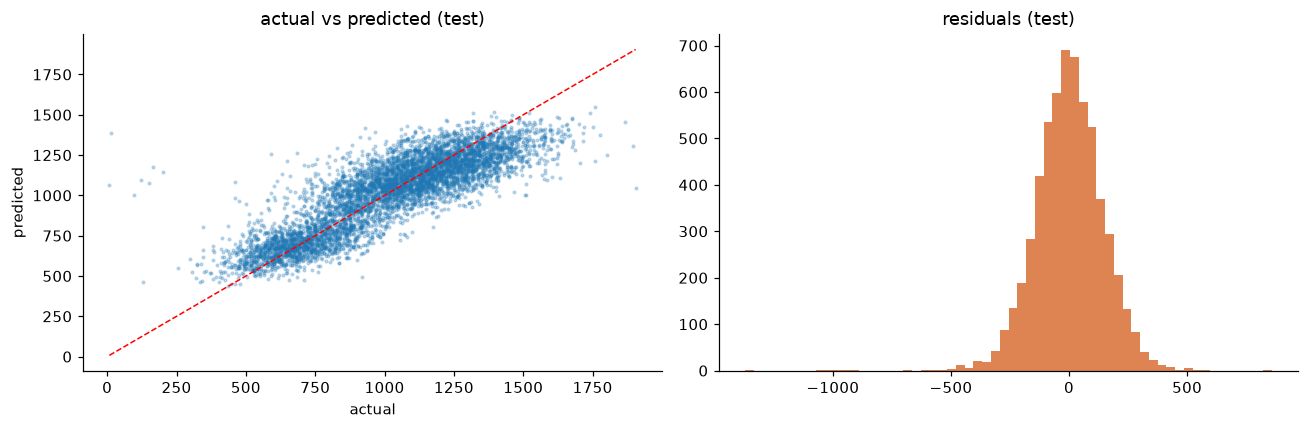

In [16]:
# 3b · Where does the best model make its biggest errors?
pred = automl_all.predict(test[FEATURES_ALL]); resid = test[TARGET] - pred
err = (test.assign(abs_err=resid.abs(), resid=resid)
           .assign(sex=lambda d: np.where(d.gender_male == 1, "male", "female"),
                   training_years=lambda d: d.howlong_ord))
display(err.groupby("sex")[["abs_err", "resid"]].mean().rename(columns={"abs_err": "MAE", "resid": "mean residual"}))
display(err.groupby("training_years")[["abs_err", "resid"]].mean().rename(columns={"abs_err": "MAE", "resid": "mean residual"}))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(test[TARGET], pred, s=3, alpha=.25); lim = [test[TARGET].min(), test[TARGET].max()]
ax[0].plot(lim, lim, "r--", lw=1); ax[0].set(title="actual vs predicted (test)", xlabel="actual", ylabel="predicted")
ax[1].hist(resid, bins=60, color="#DD8452"); ax[1].set_title("residuals (test)")
plt.tight_layout(); fig.savefig(OUT / "flaml_residuals.png"); plt.show()

**1. Shallow boosted trees win, and the top three are effectively tied.**
XGBoost with limited depth (CV RMSE 143.35), XGBoost (143.37) and LightGBM (143.66) are within 0.3 lb of each other, which is well inside CV noise. FLAML settled on very small trees for all three (`max_depth=4`, `max_leaves=4`, `num_leaves=5`). That suggests total lift depends on a few **low-order interactions** (e.g. sex × body weight), not on deep, complex structure.

**2. The relationship is mostly linear.**
The best linear model (LassoLars, 153.0) is only about 10 lb (~7%) worse than the best boosted model. R² goes from 0.697 to 0.730. Non-linearity helps, but most of the signal comes from a near-linear combination of body metrics and training history. kNN is clearly worst (179.9). Distance-based models struggle here because the features are on very different scales and include label-encoded `region_code`.

**3. Validation scores are trustworthy; there is no sign of overfitting.**
For every tree and linear model, CV RMSE and held-out test RMSE are within about 1 lb (e.g. 143.35 vs 143.89 for the winner). SGD is the exception (172.3 CV vs 159.8 test), which points to an unstable optimizer rather than a useful model.

**4. There's a performance ceiling at R² ≈ 0.73 (RMSE ≈ 144 lb).**
Every strong model family converges to roughly the same error. That points to a limit in the **data**, not the algorithm: about 27% of the variance in total lift isn't explained by body metrics and survey answers. Better features (programming, competition history) would help more than more tuning.

**5. Some families were under-explored, so read their ranks cautiously.**
Random forest ended with 11 trees and extra-trees with 4. FLAML's cost-frugal search spent most of its budget on the cheaper boosting models. Their scores show what was found within the budget, not the best those algorithms can do.

**6. The same accuracy can cost very different amounts of compute.**
XGBoost reaches the winner's score with 3,700 trees, which takes 9× longer to train (3.0 s vs 0.32 s) and 4.7× longer to predict.

**7. Search behavior: the budget was not the bottleneck.**
Almost all of the improvement came in the first ~30 seconds. Best CV RMSE dropped from about 200 to 153 lb within the first couple of seconds, reached about 144 lb by ~8 s, and about 143.5 lb by ~30 s. For the remaining ~270 s the curve is essentially flat. The final winner (depth-limited XGBoost, found at 230 s of the 300 s budget) improved on the earlier best by only a few tenths of a pound, which is within CV noise.
Of the 11 trials that set a new best, LightGBM accounted for 5 and XGBoost for 3; the linear models and depth-limited XGBoost had one each. Boosted trees were the models that kept pushing the best score down, but each new best gained less than the one before.

**9. Strongest raw signals: sex and body size dominate.**
The strongest correlations with total lift are `gender_male` (r ≈ 0.72), `weight` (≈ 0.62), `height` (≈ 0.53) and `bmi` (≈ 0.43). Every training and survey feature is much weaker: training multiple times a day ≈ 0.23, number of experience answers ≈ 0.21, college sports ≈ 0.17, and years of training (`howlong_ord`) only ≈ 0.16. `region_code` is near zero, but it's label-encoded, so its numeric order means nothing and a linear correlation understates it.
Two features are negative: age (≈ −0.14) and, unexpectedly, *starting CrossFit with a coach* (≈ −0.27). The coach effect is probably confounding, not causation. For example, beginners or women may be more likely to start with a coach. That should be checked before reading anything into it.
Because sex, weight, height and BMI are strongly correlated with each other and with the target, a mostly linear model already captures most of the signal (point 2). The weak survey features also explain the R² ≈ 0.73 ceiling (point 4).

**10. Target distribution.**
Total lift is centered around 1,000–1,100 lb and runs from about 400 to 1,800 lb. It has a visible shoulder around 700–800 lb, which is consistent with two overlapping groups (women and men). The best model's RMSE of ~144 lb is therefore about 13–14% of a typical athlete's total. A few rows sit near 0–200 lb; these are probably data-entry errors that survived the cleaning filters.

**Takeaway:** a bigger time budget would barely change the result. This supports point 4: the remaining error comes from the features, not from too little tuning.

## 🏆 4 · Top-5 features

FLAML's "reported" importances are the winning model's native `feature_importances_`. Their meaning depends on the family (split counts for LightGBM, coefficients for linear models, impurity for forests), so we also compute **permutation importance on the test split** — model-agnostic and in RMSE units. The **permutation ranking** picks the top-3 subset for §5–6 (switch `TOP_FEATURE_METHOD` to `"native"` if your instructor wants the native ranking).

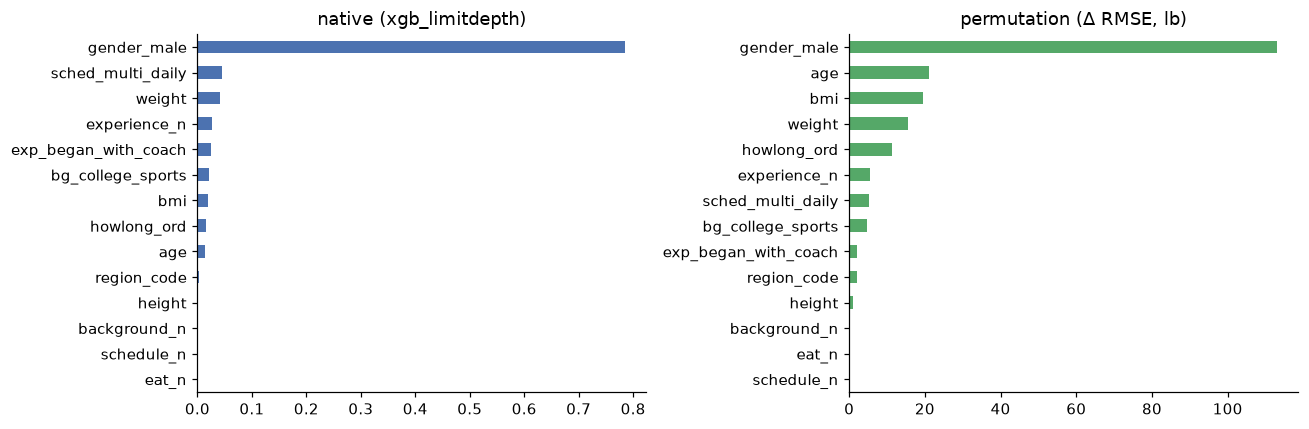

Top-5: ['gender_male', 'age', 'bmi', 'weight', 'howlong_ord'] 
Top-3 used next: ['gender_male', 'age', 'bmi']


In [18]:
TOP_FEATURE_METHOD = "permutation"   # or "native"

native = pd.Series(np.abs(automl_all.feature_importances_), index=automl_all.feature_names_in_)
native = (native / native.sum()).sort_values(ascending=False)

perm = permutation_importance(automl_all.model.estimator, test[FEATURES_ALL], test[TARGET],
                              scoring="neg_root_mean_squared_error", n_repeats=5,
                              random_state=SEED, n_jobs=-1)
perm = pd.Series(perm.importances_mean, index=FEATURES_ALL).sort_values(ascending=False)

fi_flaml = pd.DataFrame({"native_share": native, "perm_rmse_increase": perm}).sort_values(
    "perm_rmse_increase" if TOP_FEATURE_METHOD == "permutation" else "native_share", ascending=False)
TOP5_FLAML = fi_flaml.index[:5].tolist()
TOP_FEATS_FLAML = fi_flaml.index[:N_TOP_FEATS].tolist()
fi_flaml.to_csv(OUT / "flaml_feature_importance.csv")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
fi_flaml["native_share"].sort_values().plot.barh(ax=ax[0], color="#4C72B0", title=f"native ({automl_all.best_estimator})")
fi_flaml["perm_rmse_increase"].sort_values().plot.barh(ax=ax[1], color="#55A868", title="permutation (Δ RMSE, lb)")
plt.tight_layout(); fig.savefig(OUT / "flaml_feature_importance.png"); plt.show()
print("Top-5:", TOP5_FLAML, "\nTop-3 used next:", TOP_FEATS_FLAML)

## 🥇 5 · Top-3 models per validation score

### 5.1 · All features

In [19]:
SHOW = ["model", "val_rmse", "test_rmse", "test_r2", "fit_s", "predict_ms_per_1k"]
flaml_all_score, flaml_all_speed = top3_tables(lb_flaml_all, cols=SHOW)
flaml_all_score

,model,val_rmse,test_rmse,test_r2,fit_s,predict_ms_per_1k
1,xgb_limitdepth,143.351,143.891,0.730,0.322,0.732
2,xgboost,143.367,143.955,0.730,2.997,3.416
3,lgbm,143.663,144.208,0.729,0.339,1.243


### 5.2 · Only the top-3 features

In [20]:
automl_top, lb_flaml_top = run_flaml(TOP_FEATS_FLAML, "top3")
flaml_top_score, flaml_top_speed = top3_tables(lb_flaml_top, cols=SHOW)
flaml_top_score

[top3] best = xgb_limitdepth  val RMSE = 167.2  test RMSE = 167.6  (303s search)


,model,val_rmse,test_rmse,test_r2,fit_s,predict_ms_per_1k
1,xgb_limitdepth,167.165,167.557,0.634,0.189,0.438
2,xgboost,167.203,167.727,0.634,0.214,0.407
3,rf,167.411,167.622,0.634,0.317,4.520


## ⚡ 6 · Top-3 models per speed

Speed = **training time** of each family's best configuration, refit once on the full train split on this machine (`fit_s`). Prediction latency (`predict_ms_per_1k`) is shown too. A fast model is only interesting if its score is acceptable, so keep `val_rmse` next to it.

### 6.1 · All features

In [21]:
flaml_all_speed

,model,val_rmse,test_rmse,test_r2,fit_s,predict_ms_per_1k
1,lassolars,153.037,152.468,0.697,0.003,0.086
2,kneighbor,179.876,179.832,0.579,0.006,6.625
3,extra_tree,154.894,155.953,0.683,0.030,2.345


### 6.2 · Only the top-3 features

In [22]:
flaml_top_speed

,model,val_rmse,test_rmse,test_r2,fit_s,predict_ms_per_1k
1,enet,178.640,177.259,0.591,0.003,0.070
2,kneighbor,199.037,200.908,0.474,0.004,2.610
3,lassolars,178.640,177.259,0.591,0.005,0.053


## 📊 7 · AutoML vs the Part A model

The Part A model is refit here on the same split and the same machine, so both its **validation score** (5-fold CV RMSE on train, same protocol as AutoML) and its **speed** are measured exactly like the AutoML models.

In [23]:
X_tr, y_tr = train[FEATURES_ALL], train[TARGET]
cv = KFold(CV_FOLDS, shuffle=True, random_state=SEED)
partA_cv = -cross_val_score(RandomForestRegressor(**PART_A_PARAMS), X_tr, y_tr, cv=cv,
                            scoring="neg_root_mean_squared_error", n_jobs=1).mean()
_, partA_pred, partA_fit, partA_ms = time_fit_predict(lambda: RandomForestRegressor(**PART_A_PARAMS),
                                                     X_tr, y_tr, test[FEATURES_ALL])
partA_row = dict(model="Part A · RF v2 hp_light", val_rmse=partA_cv, test_rmse=rmse(test[TARGET], partA_pred),
                 test_r2=r2_score(test[TARGET], partA_pred), fit_s=partA_fit, predict_ms_per_1k=partA_ms)

compare = pd.concat([
    pd.DataFrame([partA_row]),
    lb_flaml_all.head(3)[SHOW].assign(model=lambda d: "FLAML · " + d.model + " (all)"),
    lb_flaml_top.head(1)[SHOW].assign(model=lambda d: "FLAML · " + d.model + " (top-3)"),
], ignore_index=True)
compare["Δ val_rmse vs Part A"] = compare["val_rmse"] - partA_cv
compare["speed-up vs Part A (fit)"] = partA_fit / compare["fit_s"]
compare.to_csv(OUT / "compare_partA_flaml.csv", index=False)
compare

,model,val_rmse,test_rmse,test_r2,fit_s,predict_ms_per_1k,Δ val_rmse vs Part A,speed-up vs Part A (fit)
0,Part A · RF v2 hp_light,146.493,146.900,0.719,0.228,2.392,0.000,1.000
1,FLAML · xgb_limitdepth (all),143.351,143.891,0.730,0.322,0.732,-3.143,0.707
2,FLAML · xgboost (all),143.367,143.955,0.730,2.997,3.416,-3.126,0.076
3,FLAML · lgbm (all),143.663,144.208,0.729,0.339,1.243,-2.830,0.673
4,FLAML · xgb_limitdepth (top-3),167.165,167.557,0.634,0.189,0.438,20.671,1.206


✍️ **Write-up:** does AutoML beat the hand-tuned forest on CV RMSE, by how many lb, and at what training/prediction cost? (H2O is added to this table in §10.)

## 🧩 8 · Is the platform's AutoML no-code, low-code or full-code?

**Low-code.** MLflow has no AutoML engine of its own, so AutoML here is FLAML running inside the MLflow-tracked Python workflow. The whole search (model families, hyper-parameter ranges, cross-validation, early stopping, picking the best model) is **one `AutoML.fit(...)` call** with a time budget and a metric. That is low-code: we don't write any search or tuning logic. It is not no-code because there is no point-and-click UI; you still write Python to load data, call `fit`, and log results to MLflow. It is not full-code because we never write the model-selection or tuning loop ourselves (compare Part A, where the algorithm and both hyper-parameter sets were chosen and coded by hand). The *viewing* side is no-code: runs, metrics, leaderboards and plots are browsed in the MLflow UI (`make ui`).

*(For contrast: Databricks' AutoML, which is also built on MLflow, adds a no-code UI. H2O is low-code from Python and no-code through its H2O Flow web UI.)*

## 💧 9 · Repeat 2–5 with H2O AutoML

In [24]:
import h2o
from h2o.automl import H2OAutoML, get_leaderboard

h2o.init(max_mem_size="6G", nthreads=-1, verbose=False)
h2o.no_progress()

In [25]:
def run_h2o(features, tag):
    htr = h2o.H2OFrame(train[features + [TARGET]])
    hte = h2o.H2OFrame(test[features + [TARGET]])
    aml = H2OAutoML(max_runtime_secs=H2O_BUDGET, nfolds=CV_FOLDS, seed=SEED, sort_metric="RMSE",
                    project_name=f"athletes_{tag}", verbosity=None)
    with mlflow.start_run(run_name=f"h2o_{tag}"):
        t0 = time.perf_counter(); aml.train(x=features, y=TARGET, training_frame=htr); search_s = time.perf_counter() - t0
        lb = get_leaderboard(aml, extra_columns="ALL").as_data_frame()
        lb = lb.rename(columns={"rmse": "val_rmse"})                      # CV RMSE on train
        perf = [h2o.get_model(m).model_performance(hte) for m in lb["model_id"]]
        lb["test_rmse"] = [p.rmse() for p in perf]
        lb["test_r2"] = [p.r2() for p in perf]
        lb["fit_s"] = lb["training_time_ms"] / 1000
        lb["predict_ms_per_1k"] = lb["predict_time_per_row_ms"] * 1000
        lb.to_csv(OUT / f"h2o_leaderboard_{tag}.csv", index=False)
        mlflow.log_params({"engine": "h2o", "features": ",".join(features), "n_features": len(features),
                           "max_runtime_secs": H2O_BUDGET, "cv_folds": CV_FOLDS, "leader": aml.leader.model_id})
        mlflow.log_metrics({"best_val_rmse": float(lb["val_rmse"].iloc[0]),
                            "test_rmse": float(lb["test_rmse"].iloc[0]),
                            "search_seconds": search_s, "n_models": len(lb)})
        mlflow.log_artifact(str(OUT / f"h2o_leaderboard_{tag}.csv"))
    print(f"[h2o {tag}] leader = {aml.leader.model_id}  val RMSE = {lb['val_rmse'].iloc[0]:,.1f}  "
          f"test RMSE = {lb['test_rmse'].iloc[0]:,.1f}  ({len(lb)} models, {search_s:,.0f}s)")
    return aml, lb, htr, hte

H2O_SHOW = ["model_id", "algo", "val_rmse", "test_rmse", "test_r2", "fit_s", "predict_ms_per_1k"]

### 9.2 · H2O AutoML — all features (Q2)

In [26]:
aml_all, lb_h2o_all, htr_all, hte_all = run_h2o(FEATURES_ALL, "all")
lb_h2o_all[H2O_SHOW].head(10)

/opt/anaconda3/envs/athletes-mlops/lib/python3.11/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


[h2o all] leader = StackedEnsemble_AllModels_6_AutoML_1_20261109_171518  val RMSE = 143.1  test RMSE = 143.7  (69 models, 301s)


,model_id,algo,val_rmse,test_rmse,test_r2,fit_s,predict_ms_per_1k
0,StackedEnsemble_AllModels_6_AutoML_1_20261109_...,StackedEnsemble,143.062,143.687,0.731,1.130,33.364
1,StackedEnsemble_AllModels_4_AutoML_1_20261109_...,StackedEnsemble,143.265,144.029,0.730,0.337,9.615
2,StackedEnsemble_Best1000_1_AutoML_1_20261109_1...,StackedEnsemble,143.267,144.033,0.730,0.228,9.573
3,StackedEnsemble_AllModels_3_AutoML_1_20261109_...,StackedEnsemble,143.268,144.029,0.730,0.235,9.659
4,StackedEnsemble_BestOfFamily_6_AutoML_1_202611...,StackedEnsemble,143.322,144.059,0.730,0.466,14.373
5,StackedEnsemble_BestOfFamily_4_AutoML_1_202611...,StackedEnsemble,143.356,144.085,0.730,0.260,13.637
6,GBM_grid_1_AutoML_1_20261109_171518_model_19,GBM,143.398,144.168,0.729,0.150,4.925
7,StackedEnsemble_AllModels_2_AutoML_1_20261109_...,StackedEnsemble,143.712,144.152,0.729,0.215,7.250
8,StackedEnsemble_AllModels_1_AutoML_1_20261109_...,StackedEnsemble,143.713,144.197,0.729,0.194,6.846
9,GBM_grid_1_AutoML_1_20261109_171518_model_14,GBM,143.728,144.355,0.729,0.262,4.841


### 9.3 · Data insights from H2O (Q3)

H2O's explainability module: how much each model leans on each feature, how correlated the models' predictions are, and SHAP values for the best single model.

best single model: GBM_grid_1_AutoML_1_20261109_171518_model_19


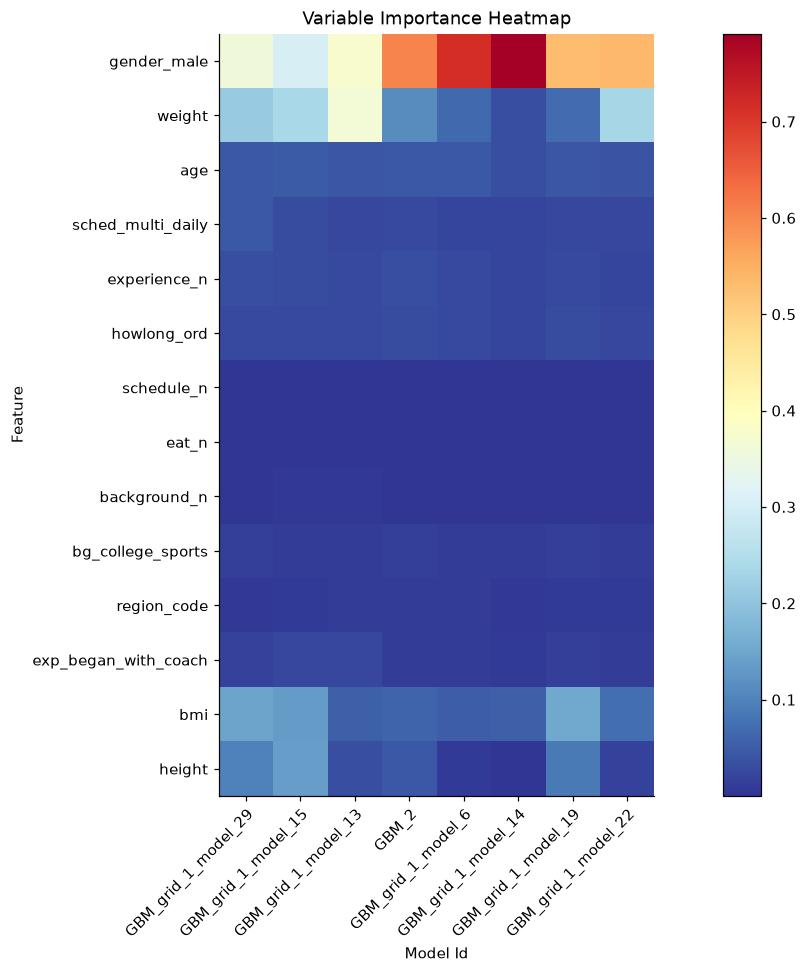

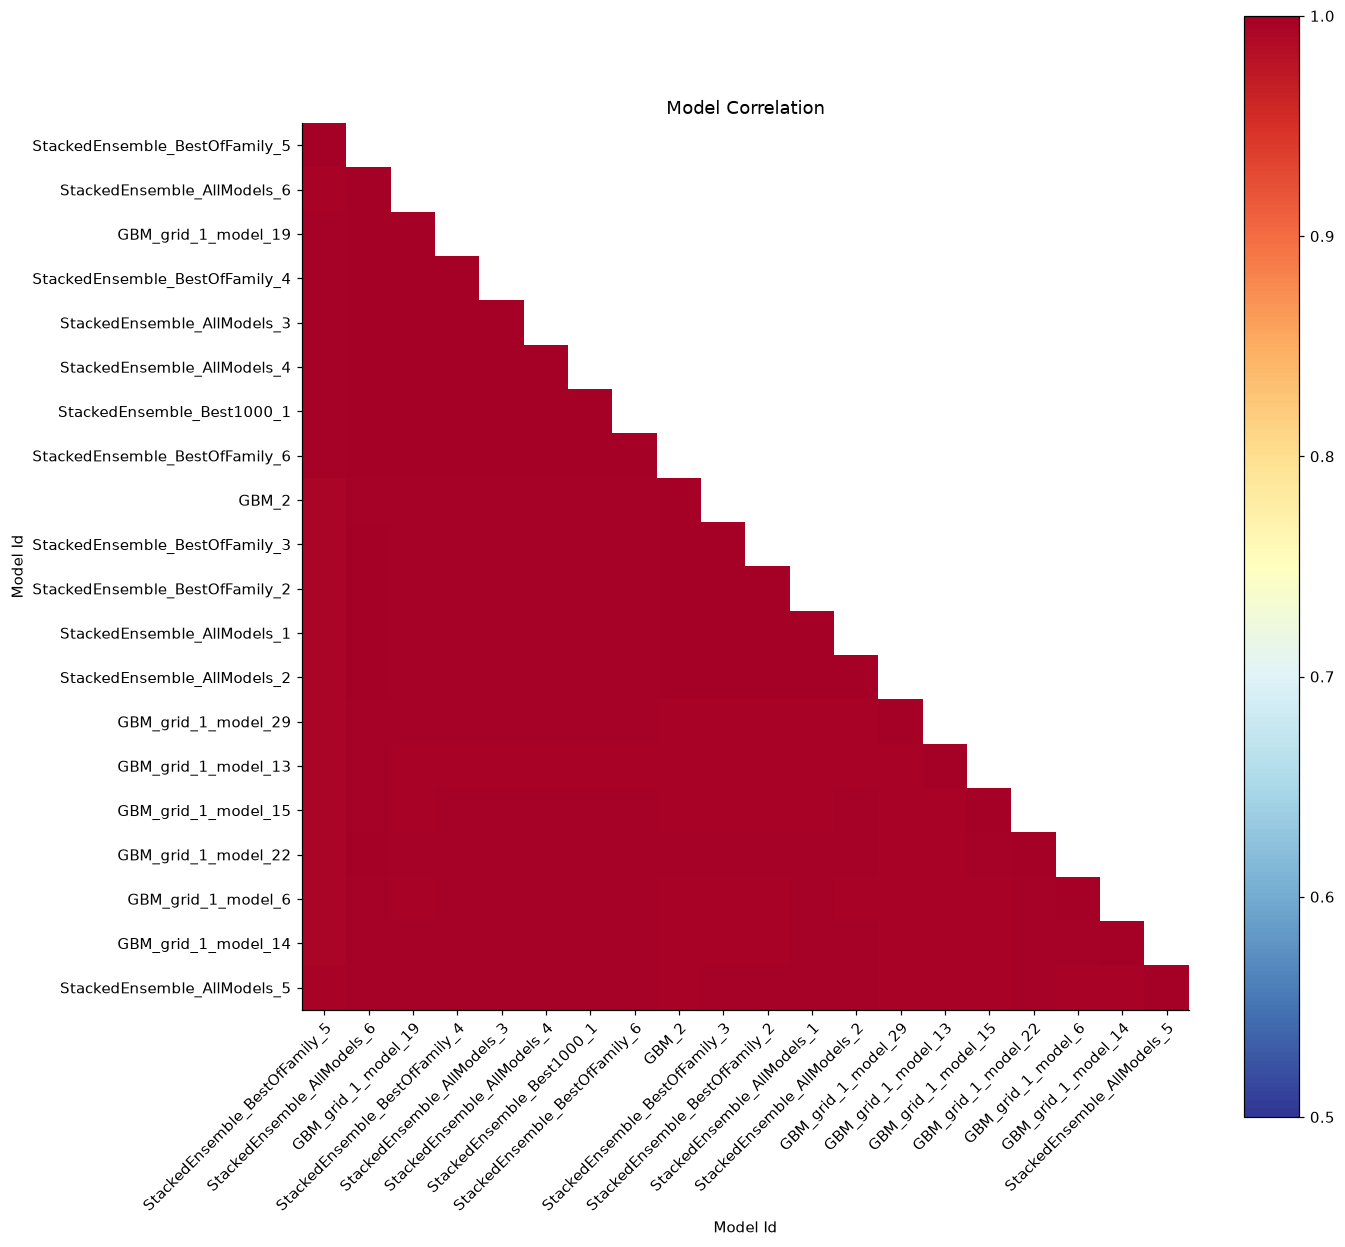

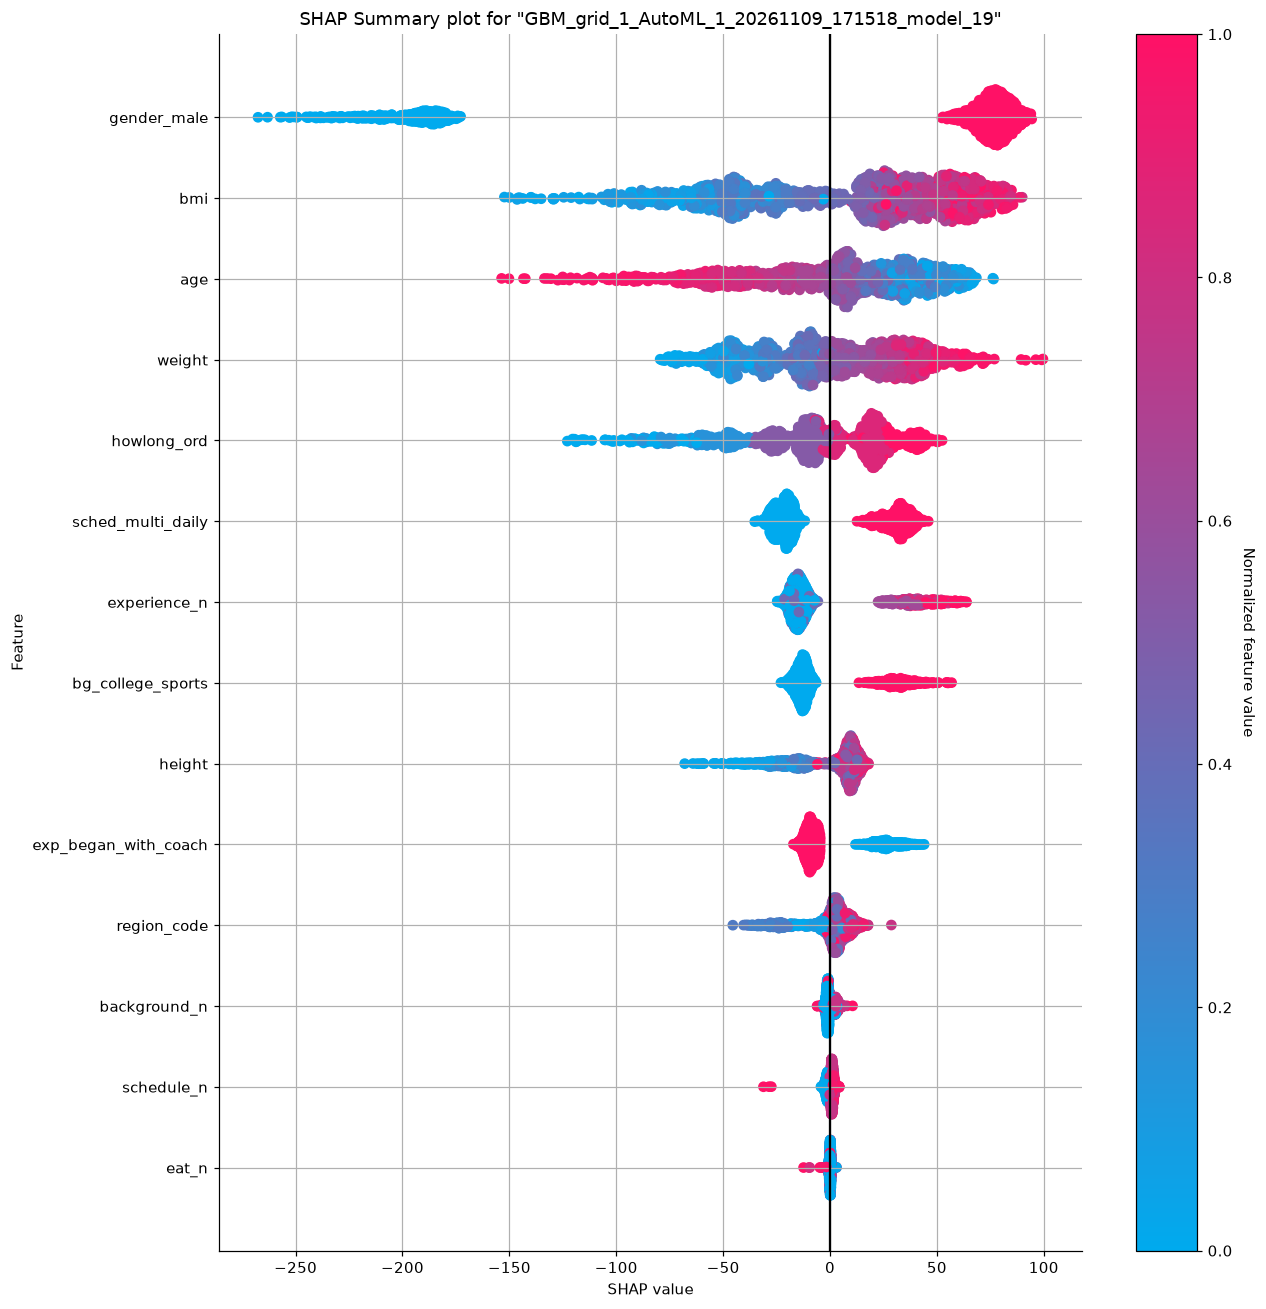

                 count     min
algo                          
StackedEnsemble     13 143.062
GBM                 37 143.398
DRF                  2 148.224
GLM                  1 153.461
DeepLearning        16 154.155


In [27]:
best_base = aml_all.get_best_model(algorithm="basemodel")   # best model that is not a stacked ensemble
print("best single model:", best_base.model_id)
aml_all.varimp_heatmap(); plt.savefig(OUT / "h2o_varimp_heatmap.png", bbox_inches="tight"); plt.show()
aml_all.model_correlation_heatmap(hte_all); plt.savefig(OUT / "h2o_model_correlation.png", bbox_inches="tight"); plt.show()
try:
    bg = htr_all[:1000, :] if best_base.algo == "glm" else None     # GLM SHAP needs a background frame
    best_base.shap_summary_plot(hte_all, background_frame=bg)
    plt.savefig(OUT / "h2o_shap_summary.png", bbox_inches="tight"); plt.show()
except Exception as e:
    print("SHAP summary skipped:", e)
print(lb_h2o_all.groupby("algo")["val_rmse"].agg(["count", "min"]).sort_values("min"))

### 9.4 · Top-5 features — H2O (Q4)

Stacked ensembles have no variable importance, so H2O reports it for the **best single model** (scaled importance, 1.0 = most important).

In [28]:
fi_h2o = best_base.varimp(use_pandas=True)[["variable", "scaled_importance", "percentage"]]
TOP5_H2O = fi_h2o["variable"].head(5).tolist()
TOP_FEATS_H2O = fi_h2o["variable"].head(N_TOP_FEATS).tolist()
fi_h2o.to_csv(OUT / "h2o_feature_importance.csv", index=False)
display(fi_h2o.head(5))
print("Top-3 used next:", TOP_FEATS_H2O)

,variable,scaled_importance,percentage
0,gender_male,1.000,0.531
1,bmi,0.287,0.153
2,height,0.165,0.087
3,weight,0.134,0.071
4,age,0.077,0.041


Top-3 used next: ['gender_male', 'bmi', 'height']


### 9.5 · Top-3 models per validation score (Q5) and per speed (Q6) — H2O

⚠️ For **stacked ensembles**, H2O's `training_time_ms` only counts the metalearner, not the base models it stacks, so their training "speed" is misleading. The speed ranking below therefore **excludes stacked ensembles**. Prediction time for ensembles *does* include their base models.

In [29]:
aml_top, lb_h2o_top, _, _ = run_h2o(TOP_FEATS_H2O, "top3")

def h2o_tables(lb):
    by_score = lb.nsmallest(3, "val_rmse")[H2O_SHOW].reset_index(drop=True)
    by_speed = lb[lb["algo"] != "StackedEnsemble"].nsmallest(3, "fit_s")[H2O_SHOW].reset_index(drop=True)
    by_score.index = by_speed.index = [1, 2, 3]
    return by_score, by_speed

h2o_all_score, h2o_all_speed = h2o_tables(lb_h2o_all)
h2o_top_score, h2o_top_speed = h2o_tables(lb_h2o_top)
for title, t in [("validation · all features", h2o_all_score), ("validation · top-3 features", h2o_top_score),
                 ("speed · all features", h2o_all_speed), ("speed · top-3 features", h2o_top_speed)]:
    print(f"\n▶ H2O top-3 by {title}"); display(t)

/opt/anaconda3/envs/athletes-mlops/lib/python3.11/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


[h2o top3] leader = StackedEnsemble_BestOfFamily_7_AutoML_2_20261109_172044  val RMSE = 174.8  test RMSE = 174.7  (74 models, 300s)

▶ H2O top-3 by validation · all features


,model_id,algo,val_rmse,test_rmse,test_r2,fit_s,predict_ms_per_1k
1,StackedEnsemble_AllModels_6_AutoML_1_20261109_...,StackedEnsemble,143.062,143.687,0.731,1.130,33.364
2,StackedEnsemble_AllModels_4_AutoML_1_20261109_...,StackedEnsemble,143.265,144.029,0.730,0.337,9.615
3,StackedEnsemble_Best1000_1_AutoML_1_20261109_1...,StackedEnsemble,143.267,144.033,0.730,0.228,9.573



▶ H2O top-3 by validation · top-3 features


,model_id,algo,val_rmse,test_rmse,test_r2,fit_s,predict_ms_per_1k
1,StackedEnsemble_BestOfFamily_7_AutoML_2_202611...,StackedEnsemble,174.809,174.743,0.602,0.265,6.459
2,StackedEnsemble_Best1000_1_AutoML_2_20261109_1...,StackedEnsemble,174.811,174.671,0.603,0.440,15.620
3,GBM_grid_1_AutoML_2_20261109_172044_model_57,GBM,174.845,174.699,0.603,0.069,2.875



▶ H2O top-3 by speed · all features


,model_id,algo,val_rmse,test_rmse,test_r2,fit_s,predict_ms_per_1k
1,GBM_grid_1_AutoML_1_20261109_171518_model_61,GBM,274.882,274.563,0.019,0.003,0.153
2,GBM_grid_1_AutoML_1_20261109_171518_model_60,GBM,181.370,181.390,0.572,0.030,1.012
3,DeepLearning_grid_1_AutoML_1_20261109_171518_m...,DeepLearning,199.434,158.050,0.675,0.048,1.065



▶ H2O top-3 by speed · top-3 features


,model_id,algo,val_rmse,test_rmse,test_r2,fit_s,predict_ms_per_1k
1,GLM_1_AutoML_2_20261109_172044,GLM,183.887,182.457,0.567,0.019,0.071
2,GBM_grid_1_AutoML_2_20261109_172044_model_62,GBM,207.207,209.445,0.429,0.021,0.673
3,DeepLearning_grid_1_AutoML_2_20261109_172044_m...,DeepLearning,199.852,188.823,0.536,0.049,0.623


## 🧾 10 · Summary for the report

In [30]:
h2o_rows = pd.concat([
    lb_h2o_all.head(1).assign(model=lambda d: "H2O · " + d.algo + " (all)"),
    lb_h2o_top.head(1).assign(model=lambda d: "H2O · " + d.algo + " (top-3)"),
])[["model", "val_rmse", "test_rmse", "test_r2", "fit_s", "predict_ms_per_1k"]]
h2o_rows["Δ val_rmse vs Part A"] = h2o_rows["val_rmse"] - partA_cv
h2o_rows["speed-up vs Part A (fit)"] = partA_fit / h2o_rows["fit_s"]
compare_all = pd.concat([compare, h2o_rows], ignore_index=True)
compare_all.to_csv(OUT / "compare_all.csv", index=False)

def md_table(d, cols):
    return d[cols].to_markdown(index=True, floatfmt=",.3f")

report = f'''# AutoML results

**Data:** {len(train):,} train / {len(test):,} test rows (same split as Part A) · {len(FEATURES_ALL)} features · target `{TARGET}`
**Budgets:** FLAML {FLAML_BUDGET}s per run · H2O {H2O_BUDGET}s per run · validation = {CV_FOLDS}-fold CV RMSE on train

## Platform (MLflow + FLAML)
- Best model: **{automl_all.best_estimator}** · CV RMSE {automl_all.best_loss:,.1f} lb
- Top-5 features ({TOP_FEATURE_METHOD}): {", ".join(TOP5_FLAML)}
- Top-3 subset: {", ".join(TOP_FEATS_FLAML)}

### Top-3 by validation score — all features
{md_table(flaml_all_score, SHOW)}

### Top-3 by validation score — top-3 features
{md_table(flaml_top_score, SHOW)}

### Top-3 by speed (fit time) — all features
{md_table(flaml_all_speed, SHOW)}

### Top-3 by speed (fit time) — top-3 features
{md_table(flaml_top_speed, SHOW)}

## H2O AutoML
- Leader: **{aml_all.leader.model_id}** · best single model {best_base.model_id}
- Top-5 features: {", ".join(TOP5_H2O)}

### Top-3 by validation score — all features
{md_table(h2o_all_score, H2O_SHOW)}

### Top-3 by validation score — top-3 features
{md_table(h2o_top_score, H2O_SHOW)}

### Top-3 by speed (fit time, excl. stacked ensembles) — all features
{md_table(h2o_all_speed, H2O_SHOW)}

### Top-3 by speed (fit time, excl. stacked ensembles) — top-3 features
{md_table(h2o_top_speed, H2O_SHOW)}

## vs Part A (RandomForest · v2 · hp_light)
{compare_all.to_markdown(index=False, floatfmt=",.3f")}
'''
(OUT / "results.md").write_text(report)
with mlflow.start_run(run_name="automl_summary"):
    mlflow.log_artifacts(str(OUT))
print(report)

# AutoML results

**Data:** 24,023 train / 6,006 test rows (same split as Part A) · 14 features · target `total_lift`
**Budgets:** FLAML 300s per run · H2O 300s per run · validation = 5-fold CV RMSE on train

## Platform (MLflow + FLAML)
- Best model: **xgb_limitdepth** · CV RMSE 143.4 lb
- Top-5 features (permutation): gender_male, age, bmi, weight, howlong_ord
- Top-3 subset: gender_male, age, bmi

### Top-3 by validation score — all features
|    | model          |   val_rmse |   test_rmse |   test_r2 |   fit_s |   predict_ms_per_1k |
|---:|:---------------|-----------:|------------:|----------:|--------:|--------------------:|
|  1 | xgb_limitdepth |    143.351 |     143.891 |     0.730 |   0.322 |               0.732 |
|  2 | xgboost        |    143.367 |     143.955 |     0.730 |   2.997 |               3.416 |
|  3 | lgbm           |    143.663 |     144.208 |     0.729 |   0.339 |               1.243 |

### Top-3 by validation score — top-3 features
|    | model          |   va

In [31]:
h2o.cluster().shutdown()